# 03 - Customer segmentation (RFM)

**Question.** Which customers are valuable, which are slipping away, and how should each
group be treated?

**Method.** Score every buyer 1-5 on three dimensions, measured at the snapshot date
(1 January 2026, the day after the data ends):

- **Recency:** days since last order, scored in quintiles (5 = most recent).
- **Frequency:** number of delivered orders, scored with fixed bins (1, 2, 3, 4-5, 6+
  orders). About half of buyers have exactly one order, so quintiles of tied values would
  split identical customers at random.
- **Monetary:** total net revenue, scored in quintiles (5 = highest).

Segments are named from recency and frequency with simple ordered rules. Monetary value is
reported per segment rather than used in the rules, which keeps the rules easy to explain.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().resolve().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import metrics, plots
from src.common import load_config, project_path

cfg = load_config()
conn = metrics.open_db(cfg)
FIGURES = project_path(cfg["paths"]["figures_dir"])
pd.set_option("display.float_format", "{:,.2f}".format)
plots.apply_style()

In [2]:
customers, churn_rule = metrics.build_customer_table(conn, cfg)
pd.DataFrame(metrics.SEGMENT_RULES, columns=["segment", "rule (r = recency score, f = frequency score)"])

,segment,"rule (r = recency score, f = frequency score)"
0,Champions,r >= 4 and f >= 4
1,Loyal,r >= 3 and f >= 3
2,New,r >= 4 and f == 1
3,Promising,r >= 4
4,At Risk,r <= 2 and f >= 3
5,Hibernating,r <= 2
6,Needs Attention,r == 3


## Segment profiles

In [3]:
profile = metrics.segment_profile(customers)
profile.style.format({
    "customer_share": "{:.1%}", "revenue_share": "{:.1%}", "revenue": "{:,.0f}",
    "avg_recency_days": "{:,.0f}", "avg_orders": "{:.1f}", "avg_revenue": "{:,.0f}",
    "avg_discount_share": "{:.0%}", "avg_return_rate": "{:.1%}",
})

,customers,customer_share,revenue,revenue_share,avg_recency_days,avg_orders,avg_revenue,avg_discount_share,avg_return_rate
rfm_segment,,,,,,,,,
Champions,186,15.4%,"8,886,090",49.6%,59,9.7,"47,775",20%,7.0%
Loyal,123,10.2%,"2,522,986",14.1%,261,4.8,"20,512",38%,7.8%
New,195,16.1%,"785,576",4.4%,107,1.0,"4,029",38%,8.2%
Promising,61,5.0%,"480,352",2.7%,78,2.0,"7,875",39%,7.6%
At Risk,118,9.8%,"2,356,804",13.2%,726,4.5,"19,973",40%,7.9%
Hibernating,365,30.2%,"1,936,754",10.8%,814,1.2,"5,306",42%,9.2%
Needs Attention,160,13.2%,"952,266",5.3%,348,1.2,"5,952",40%,9.6%


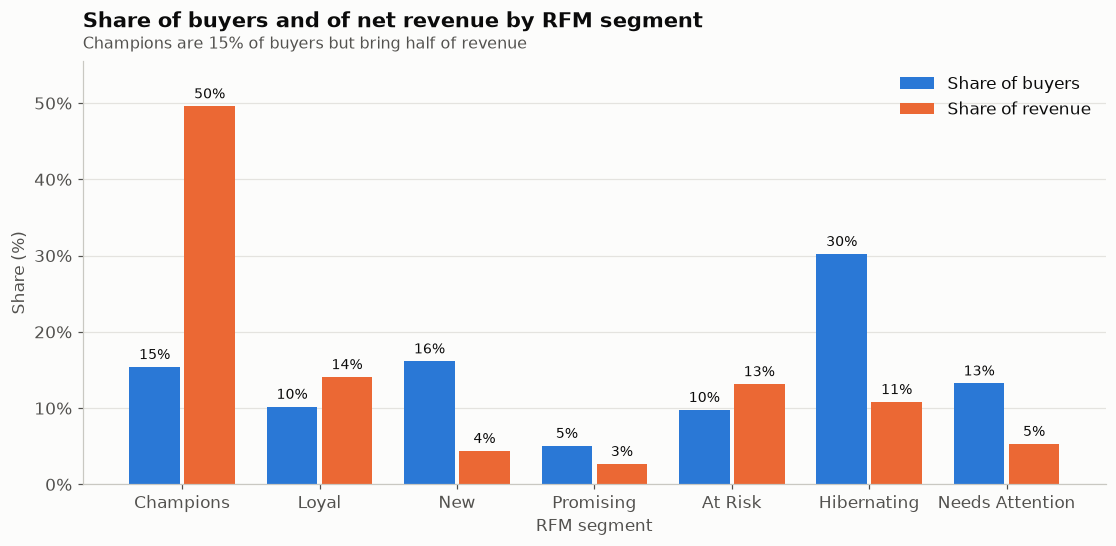

In [4]:
shares = profile[["customer_share", "revenue_share"]].rename(
    columns={"customer_share": "Share of buyers", "revenue_share": "Share of revenue"})

fig, ax = plots.new_figure(12, 5)
plots.grouped_bar_chart(ax, shares)
plots.format_axis(ax, "y", "pct")
plots.set_titles(ax, "Share of buyers and of net revenue by RFM segment",
                 "Champions are 15% of buyers but bring half of revenue")
ax.set_xlabel("RFM segment")
ax.set_ylabel("Share (%)")
plots.save_figure(fig, FIGURES / "03_segment_shares.png")
plt.show()

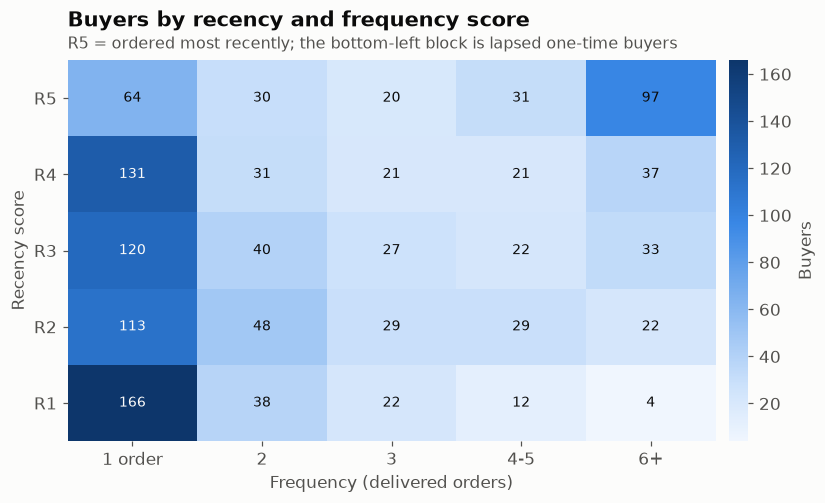

In [5]:
grid = customers.pivot_table(index="r", columns="f", values="customer_id", aggfunc="count", fill_value=0)
grid = grid.sort_index(ascending=False)
grid.columns = ["1 order", "2", "3", "4-5", "6+"]
grid.index = [f"R{r}" for r in grid.index]

fig, ax = plots.new_figure(8, 4.5)
plots.heatmap(ax, grid, value_format="{:.0f}", colorbar_label="Buyers")
plots.set_titles(ax, "Buyers by recency and frequency score",
                 "R5 = ordered most recently; the bottom-left block is lapsed one-time buyers")
ax.set_xlabel("Frequency (delivered orders)")
ax.set_ylabel("Recency score")
plots.save_figure(fig, FIGURES / "03_rfm_grid.png")
plt.show()

## Segment churn and value

In [6]:
judged = customers[customers["churn_status"] != "too_new"]
segment_view = pd.DataFrame({
    "buyers": customers.groupby("rfm_segment", observed=True).size(),
    "churn_rate": judged.groupby("rfm_segment", observed=True)["churned"].mean(),
    "revenue_bdt": customers.groupby("rfm_segment", observed=True)["revenue"].sum(),
})
segment_view.style.format({"churn_rate": "{:.0%}", "revenue_bdt": "{:,.0f}"})

,buyers,churn_rate,revenue_bdt
rfm_segment,,,
Champions,186,14%,"8,886,090"
Loyal,123,80%,"2,522,986"
New,195,100%,"785,576"
Promising,61,39%,"480,352"
At Risk,118,100%,"2,356,804"
Hibernating,365,100%,"1,936,754"
Needs Attention,160,100%,"952,266"


## Check against the hidden behaviour types

The generator gave each customer a hidden type. The analysis never uses it, but checking
against it shows whether RFM recovers real behaviour. Each row shows what share of a
segment's customers belong to each hidden type.

In [7]:
truth = pd.read_csv(project_path(cfg["paths"]["customer_truth"]))[["customer_id", "customer_type"]]
check = customers.merge(truth, on="customer_id")
pd.crosstab(check["rfm_segment"], check["customer_type"], normalize="index").style.format("{:.0%}")

customer_type,discount_seeker,high_value,loyal,one_time,regular,seasonal
rfm_segment,,,,,,
Champions,4%,12%,49%,0%,32%,3%
Loyal,19%,11%,18%,0%,40%,13%
New,19%,2%,3%,35%,22%,19%
Promising,13%,10%,23%,0%,39%,15%
At Risk,23%,10%,14%,0%,38%,15%
Hibernating,24%,3%,3%,34%,22%,15%
Needs Attention,19%,4%,4%,31%,22%,21%


Champions are mostly the hidden "loyal", "regular" and "high_value" types, and none are
one-time buyers. Hibernating is dominated by one-time buyers and discount seekers. RFM is
recovering real behaviour, not just noise.

## Findings and recommendations

| Segment | Buyers | Revenue share | What it means | Recommended action |
|---|---|---|---|---|
| Champions | 186 (15%) | 50% | Frequent (9.7 orders), recent (59 days) | Protect: early access to 11.11 and Eid sales, priority delivery. No blanket discounts; they already use them least (20% of orders). |
| Loyal | 123 (10%) | 14% | Frequent but last seen 261 days ago | Re-engage before they drift: personalised picks based on past categories. |
| At Risk | 118 (10%) | 13% | Used to buy often (4.5 orders), silent for about 2 years | Win-back campaign. This is the largest pool of past value worth chasing. |
| New | 195 (16%) | 4% | One recent order | Second-order nudge within the typical 38-day repeat window. |
| Promising | 61 (5%) | 3% | Two recent orders | Loyalty enrolment. |
| Needs Attention | 160 (13%) | 5% | One or two orders, mid recency | Low-cost reminders only. |
| Hibernating | 365 (30%) | 11% | Mostly one-off buyers who never returned | Do not spend acquisition-level budgets here. |

The value is concentrated: Champions and Loyal together are a quarter of buyers and nearly
two-thirds of revenue.